# 1. Experiment 4 — Independent verifier effectiveness

**H4.** The deterministic verifier will detect explicit structured attribution errors more
reliably than mathematical errors embedded in complex prose, and will falsely reject more
faithful explanations written in unfamiliar ways.

A mathematical error is a claim that disagrees with the supplied fitted model or SHAP
reference, or asserts knowledge that the reference cannot support. Release is a separate
decision. This experiment compares explicit error detection with conservative rejection on
the same independently labeled cases. Positive means mathematically unfaithful.

/Users/sghosh/Documents/Github/AI380H/HRP/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


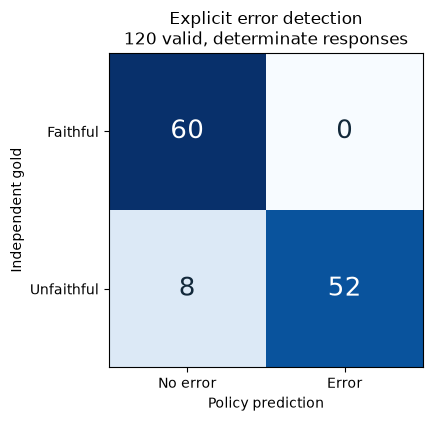

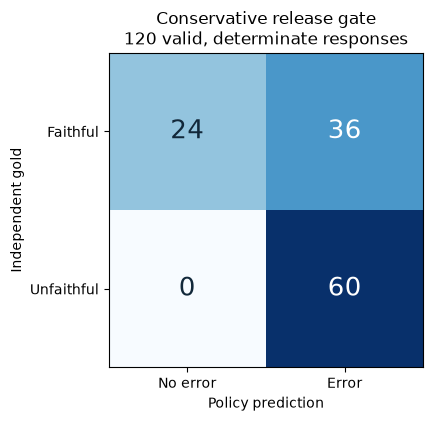

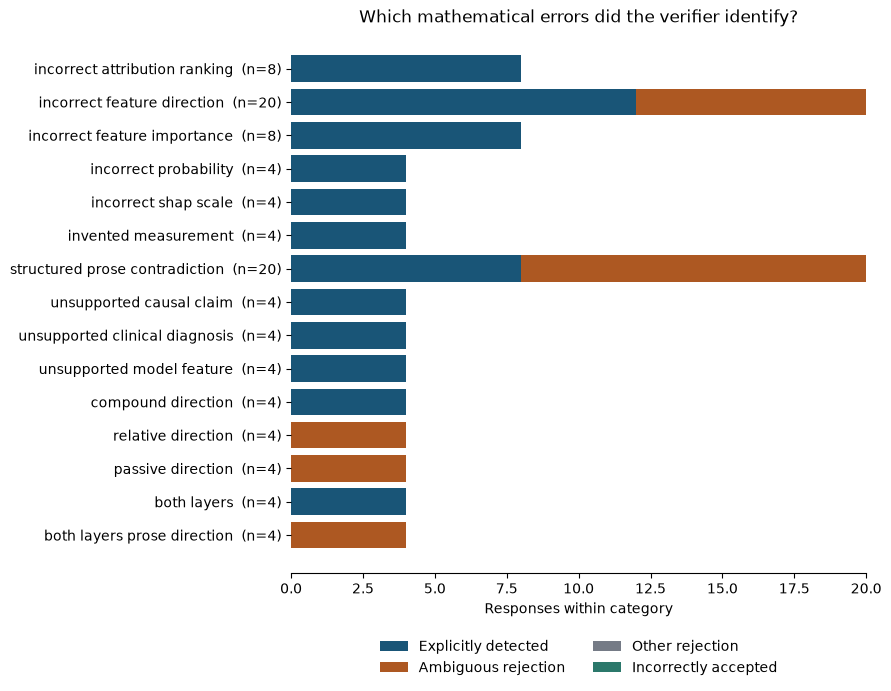

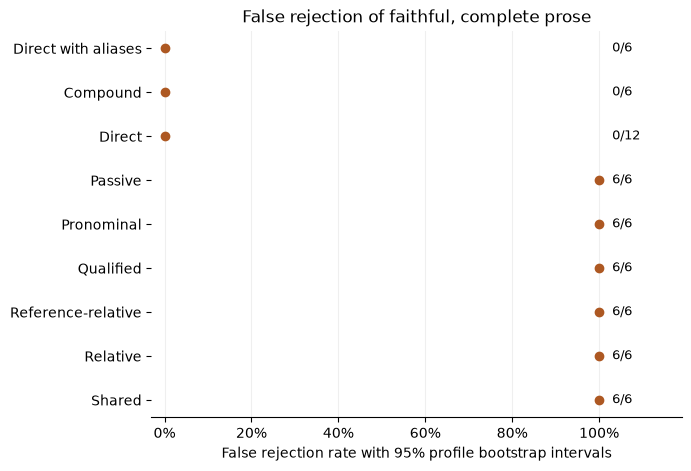

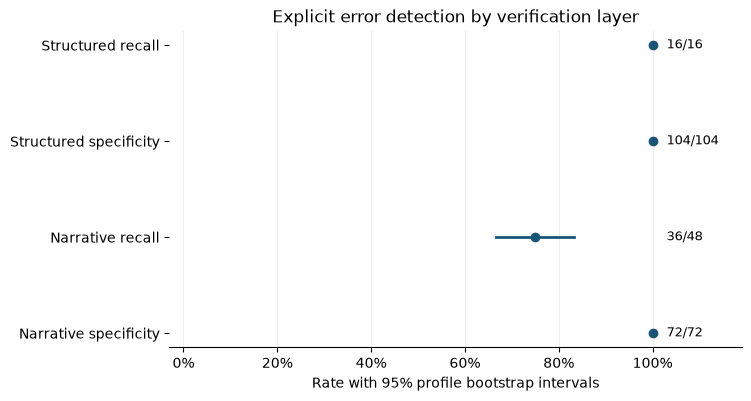

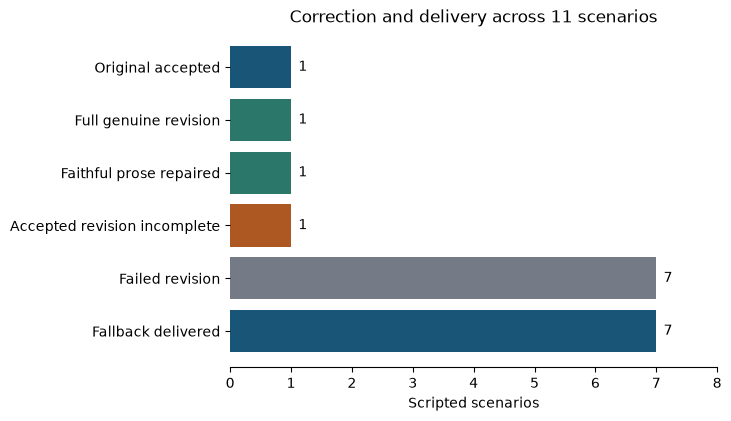

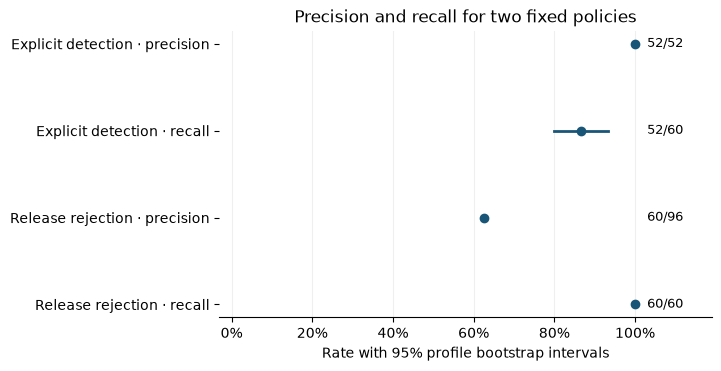

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

for candidate in (Path.cwd(), Path.cwd() / "src", Path.cwd() / "HRP" / "src"):
    if (candidate / "verifier_evaluation.py").is_file():
        SOURCE = candidate.resolve()
        sys.path.insert(0, str(SOURCE))
        break
else:
    raise FileNotFoundError("Launch the kernel from HRP, HRP/src, or the repository root.")

from verifier_challenge_set import FIXTURE, ROOT
from verifier_correction import saved_prose_worksheet
from verifier_evaluation import notebook_run
from verifier_evaluation_figures import build_figures

MODE = "review"  # setup, review, evaluate, fictional, live_revision
RESULTS_DIRECTORY = FIXTURE / "results"
SAVE_EVALUATION = False
LIVE_DIRECTORY = None  # Set a dedicated owner-only path outside Git for live_revision.
MAX_LIVE_CALLS = 30    # Cumulative generation budget. No model is started by this notebook.
AUDIT_EXPERIMENT = None  # Set to 2 or 3 explicitly to create a private saved-prose worksheet.
AUDIT_DIRECTORY = None

run = notebook_run(MODE, directory=RESULTS_DIRECTORY, save=SAVE_EVALUATION,
                   live_directory=LIVE_DIRECTORY, max_calls=MAX_LIVE_CALLS)
bundle = run["bundle"]
gold = pd.DataFrame(bundle["labels"])
analysis = run.get("analysis")
correction = run.get("corrections")
figures = build_figures(analysis, correction) if analysis else {}

def show_figure(name):
    if name in figures:
        display(figures[name])
        plt.close(figures[name])

def metric_frame(metrics):
    return pd.DataFrame(metrics).T.round(3)

## 2. Frozen verifier architecture

The Experiment 2/3 path parses the JSON response and checks the structured feature keys,
directions, order and omissions against SHAP. The narrative grammar checks each clause
against the reference and the submitted driver directions. The release gate requires
supported directional prose for every expected driver. A rejected draft may receive one
revision. Failed revisions use a deterministic explanation derived from the reference.
The run validates the committed source-file hashes before execution or offline review.

In [2]:
display(pd.Series({key: value for key, value in run["frozen"].items() if key != "files"}))
display(pd.Series(run["frozen"]["files"], name="SHA-256"))

version                                  experiment2-verifier-v3
code_sha256    ddf413feffe3b14925cccff67f0fcd996a3dc28ae40c8a...
commit                                                   a51a7b1
dtype: object

llm_verification.py      8587981795811045a74ae26f43d3563111cf52860734d6...
narrative_verifier.py    9fc388cf26fd1fcd0d13c11d9ac4877e2674d11e3b76d2...
llm_runner.py            28a32ed3c020046be2835e3a2476cf79402db3db6196f1...
hrp_faithfulness.py      3a91cc7691bf10f3c2c72b861a7c0eadb944dec563cec5...
experiment2_inputs.py    dc47bf586c4440f8a2ccfcddc54402c74c8a6b2ec64c5e...
Name: SHA-256, dtype: object

## 3. Independent gold-labeling rubric

Faithfulness, completeness and schema validity are labeled independently. Faithful
abstention and faithful malformed prose are possible. Indeterminate means the author
cannot resolve a material semantic claim. Completeness describes the presence of the
probability, required drivers and their prose directions. The authored claim annotations
identify the quantity, reference, feature, wording, status and applicable errors.

In [3]:
display(Markdown((ROOT / "rubric.md").read_text()))

# Experiment 4 gold rubric and design

Judge claims from the supplied fitted-model reference before exposing verifier
outputs. A response is **faithful** when its explicit assessable claims agree,
**unfaithful** when any claim is contradicted or asserts knowledge the reference
cannot support, and **indeterminate** when unresolved meaning could change the
judgment and no claim is known false. Abstention can be faithful. A malformed
response can contain faithful prose. Schema validity refers to the two-key
JSON contract, known unique feature names, up to three drivers, binary
directions, and an explanation of 1–90 words. Sentence count is advisory.
Plain text has no response-schema judgment.

Completeness requires the predicted probability, every non-negligible top-three
driver in the list, and each top-three direction in prose. Presence and
correctness are judged separately. Structured rank correctness uses the
reference ordering, including its explicit tie-break. Prose may truthfully
describe tied contributions as jointly strongest. Compare SHAP magnitudes for
rank and treat absolute values at most 1e-8 as negligible. Direction describes
a local contribution in raw log-odds under an increasing logistic link.
Compare displayed probabilities at their stated precision. Raw SHAP units are
not probability points. Imputation does not establish that a lab was measured.
Feature attribution cannot establish a diagnosis or clinical causality.

Record each claim's text, layer, feature, stated quantity, reference quantity,
status, and applicable errors. Categories cover direction, importance, rank,
probability, unsupported feature use, measurement, missingness, SHAP scale,
causality, diagnosis, JSON/prose conflict, omission, ambiguity, and malformed
responses. Overlapping error categories count once per case per category.

Twelve linear logistic references form six paired profiles with fixed patient
features and reversed coefficients. Each reference contributes five faithful
paraphrases, five controlled corruptions, and five boundary cases. The direct
control is paired with all four alternative wordings. Recipes and wordings
are assigned by a fixed rotation. The planned primary comparison uses valid,
determinate A and B responses with mathematical errors as positives. Group C
is a separate boundary cohort. A sensitivity analysis includes all valid,
determinate examples. Bootstrap samples draw entire profiles, retaining both
coefficient directions and matched paraphrases. These are authored gold
judgments. Independent human review has not occurred.

For optional live correction, rank candidate IDs by a fixed seeded hash and
take ten rejected examples from each of groups B errors, A faithful prose, and
C faithful valid incomplete responses. One correction request per ID, local
Qwen3 8B only, temperature zero, seed 42, and the Experiment 2/3 model digest.
A returned revision remains pending independent annotation.


## 4. Challenge construction

Group A contains faithful complete responses. Group B contains controlled corruptions.
Group C contains incomplete, indeterminate and malformed responses, plus several
unsupported or factually incorrect statements. The same probability and attributions
underlie each direct control and its four paraphrases. Structured probes keep the prose
fixed. Each raw response is unique. Error categories overlap when one edit affects both
the reference comparison and the agreement between prose and JSON.

In [4]:
display(pd.crosstab(gold["group"], gold["faithfulness"], margins=True))
display(pd.crosstab(gold["group"], gold["linguistic_construction"]))
error_rows = gold[["group", "errors"]].explode("errors", ignore_index=True)
display(pd.crosstab(error_rows["group"], error_rows["errors"]).T)

faithfulness,faithful,indeterminate,unfaithful,All
group,,,,
A,60,0,0,60
B,0,0,60,60
C,44,8,8,60
All,104,8,68,180


linguistic_construction,coordinated_or_compound,direct,hedged_or_qualified,implicit_reference_or_pronoun,other,passive,relative_clause,shared_predicate
group,,,,,,,,
A,6,18,6,6,6,6,6,6
B,4,44,0,0,0,4,8,0
C,0,44,4,4,8,0,0,0


group,B,C
errors,,
ambiguous_or_indeterminate,0,8
incorrect_attribution_ranking,8,0
incorrect_feature_direction,20,0
incorrect_feature_importance,8,0
incorrect_missing_value,0,4
incorrect_probability,4,0
incorrect_shap_scale,4,0
invented_measurement,4,0
malformed_response,0,24


## 5. Reference and label validation

Twelve additive logistic references form six fictional profiles. Each profile has fixed
measurements and reversed coefficient directions. The references include exact ties,
missing measurements, mixed signs, outside-top-three features and near-zero effects.
The validation rechecks the linear model, SHAP additivity, logistic consistency, case links
and the deterministic reconstruction of inputs and annotations. The worksheet and separate
crosswalk support blinded double review. Independent human review is pending.

In [5]:
display(pd.Series(run["validation"]))

examples                                                          180
references                                                         12
clusters                                                            6
groups                                    {'A': 60, 'B': 60, 'C': 60}
gold_counts         {'faithful': 104, 'unfaithful': 68, 'indetermi...
max_residuals       {'additivity': 8.881784197001252e-16, 'logit':...
challenge_sha256    64840e4744bab0fe457767056cc474856144db5c4a2719...
dtype: object

## 6. Frozen verifier execution

Review reads the checksummed evaluation bundle offline. Evaluate replays every input
without Ollama. Gold labels are joined after the verifier returns. The trace retains
schema diagnostics, structured checks, parsed clauses, missing directions and the raw
issue codes. A response may contain both an explicit issue and ambiguity. The outcome
summary gives precedence to schema failure, explicit evidence, then ambiguity and
incompleteness. The release decision is stored separately.

In [6]:
if analysis:
    display(pd.DataFrame(analysis["outcomes"]).fillna(0).astype(int))
    display(pd.DataFrame(analysis["boundary"]))
else:
    print("Use review or evaluate to display detection results.")

,A,B,C
accepted_as_faithful,24,0,0
ambiguous_or_unparsed,36,8,16
explicit_error_detected,0,52,4
incomplete_but_otherwise_correct,0,0,16
schema_invalid,0,0,24


,faithfulness,completeness,schema,outcome,n
0,faithful,incomplete,valid,ambiguous_or_unparsed,4
1,faithful,incomplete,valid,incomplete_but_otherwise_correct,16
2,faithful,not_applicable,invalid,schema_invalid,24
3,indeterminate,complete,valid,ambiguous_or_unparsed,8
4,unfaithful,complete,valid,ambiguous_or_unparsed,4
5,unfaithful,complete,valid,explicit_error_detected,4


## 7. Confusion matrices

The primary cohort includes 60 faithful and 60 unfaithful valid, determinate A/B
responses. The explicit policy predicts an error when the verifier identifies a
contradiction or unsupported claim. The release policy predicts an error whenever the
gate withholds the response. The sensitivity analysis also includes valid, determinate
Group C rows.

,TP,FP,TN,FN
explicit,52,0,60,8
release,60,36,24,0


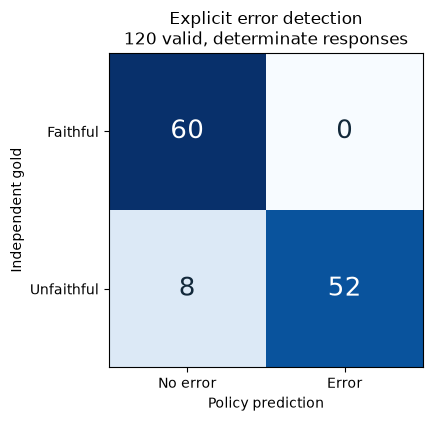

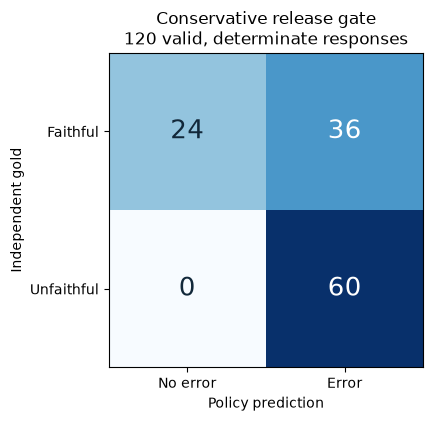

In [7]:
if analysis:
    display(pd.DataFrame({k: v["confusion"] for k, v in analysis["primary"].items()}).T)
    show_figure("01_explicit_confusion")
    show_figure("02_release_confusion")

## 8. Detection accuracy

The precision and recall estimates compare two fixed policies. F1 uses the usual count
formula and balanced accuracy averages sensitivity and specificity. The output includes
numerators, denominators and clustered 95% intervals.

numerator  denominator  ...  ci95_high  clusters
explicit precision                 52.0         52.0  ...      1.000       6.0
         recall                    52.0         60.0  ...      0.933       6.0
         specificity               60.0         60.0  ...      1.000       6.0
         false_positive_rate        0.0         60.0  ...      0.000       6.0
         false_negative_rate        8.0         60.0  ...      0.200       6.0
         f1                       104.0        112.0  ...      0.966       6.0
         balanced_accuracy       6720.0       7200.0  ...      0.967       6.0
release  precision                 60.0         96.0  ...      0.625       6.0
         recall                    60.0         60.0  ...      1.000       6.0
         specificity               24.0         60.0  ...      0.400       6.0
         false_positive_rate       36.0         60.0  ...      0.600       6.0
         false_negative_rate        0.0         60.0  ...      0.000       6.0
         f1                       120.0        156.0  ...      0.769       6.0
         balanced_accuracy       5040.0       7200.0  ...      0.700       6.0

[14 rows x 6 columns]

,TP,FP,TN,FN
explicit,56,0,80,12
release,68,56,24,0


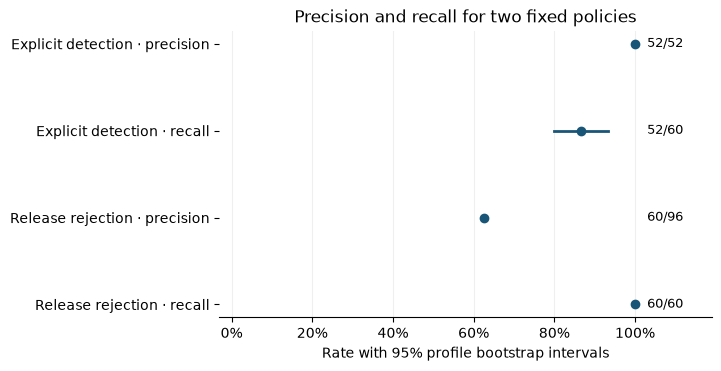

In [8]:
if analysis:
    display(pd.concat({k: metric_frame(v["metrics"]) for k, v in analysis["primary"].items()}))
    display(pd.DataFrame({k: v["confusion"] for k, v in analysis["all_eligible_sensitivity"].items()}).T)
    show_figure("07_policy_precision_recall")

## 9. False rejection of faithful prose

Compare the direct control with the same claims expressed using aliases, compound
clauses, shared predicates, relative clauses, passive voice, reference qualifiers or
pronominal references. Both versions have identical reference directions, probability
and structured drivers. The labels remain the same even when the parser cannot recover
a direction.

,accepted,false_rejection,ambiguous_rejection,missing_parsed_directions,incorrect_explicit_classification
all,24/60,36/60,36/60,36/60,0/60
alias,6/6,0/6,0/6,0/6,0/6
compound,6/6,0/6,0/6,0/6,0/6
direct,12/12,0/12,0/12,0/12,0/12
passive,0/6,6/6,6/6,6/6,0/6
pronoun,0/6,6/6,6/6,6/6,0/6
qualified,0/6,6/6,6/6,6/6,0/6
reference,0/6,6/6,6/6,6/6,0/6
relative,0/6,6/6,6/6,6/6,0/6
shared,0/6,6/6,6/6,6/6,0/6


,style,discordant,numerator,denominator,estimate,ci95_low,ci95_high,clusters
0,alias,0,0,6,0.0,0.0,0.0,6
1,compound,0,0,6,0.0,0.0,0.0,6
2,passive,6,6,6,1.0,1.0,1.0,6
3,pronoun,6,6,6,1.0,1.0,1.0,6
4,qualified,6,6,6,1.0,1.0,1.0,6
5,reference,6,6,6,1.0,1.0,1.0,6
6,relative,6,6,6,1.0,1.0,1.0,6
7,shared,6,6,6,1.0,1.0,1.0,6


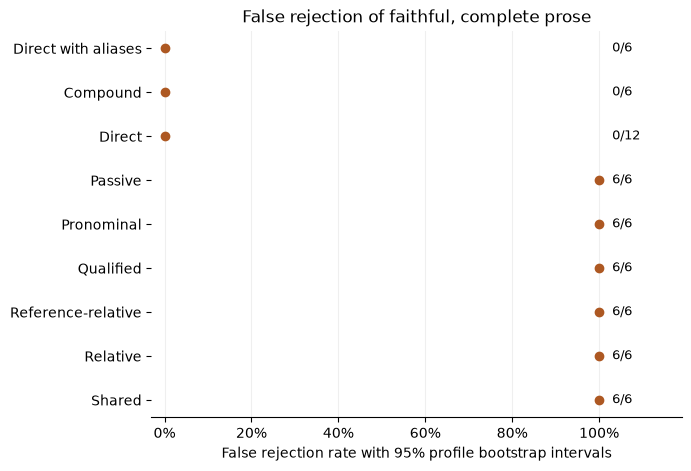

In [9]:
if analysis:
    rows = analysis["false_rejection"]
    rejection = {r["style"]: {k: f'{v["numerator"]}/{v["denominator"]}'
                              for k, v in r.items() if isinstance(v, dict)}
                 for r in rows if not r["style"].startswith("category_")}
    display(pd.DataFrame(rejection).T)
    pairs = pd.DataFrame(analysis["paraphrases"])
    display(pairs.drop(columns="pairs").round(3))
    show_figure("04_false_rejection")

## 10. Missed errors and ambiguity

A category earns explicit detection when the issue matches an authored error in that
layer and, where available, the implicated feature. A rejected example can still contain
a missed error. The table counts each response once per category and includes targeted
construction rows. These rows overlap. For example, a wrong direction can also conflict
with JSON. Detecting one error in a multi-error example can leave a second error
unexplained.

,category,n,explicitly_detected,ambiguous_rejection,incorrectly_accepted,missed_other_rejection
0,incorrect_attribution_ranking,8,8,0,0,0
1,incorrect_feature_direction,20,12,8,0,0
2,incorrect_feature_importance,8,8,0,0,0
3,incorrect_probability,4,4,0,0,0
4,incorrect_shap_scale,4,4,0,0,0
5,invented_measurement,4,4,0,0,0
6,structured_prose_contradiction,20,8,12,0,0
7,unsupported_causal_claim,4,4,0,0,0
8,unsupported_clinical_diagnosis,4,4,0,0,0
9,unsupported_model_feature,4,4,0,0,0


0    exp4-B-01-01
1    exp4-B-04-01
2    exp4-B-07-01
3    exp4-B-10-01
Name: Multiple false gold claims, dtype: object

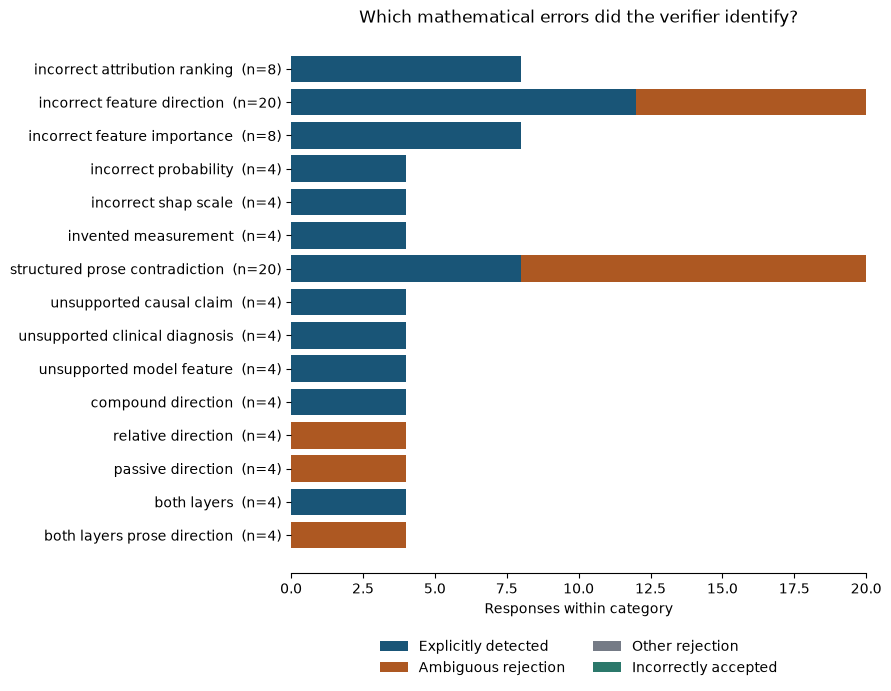

In [10]:
if analysis:
    display(pd.DataFrame([{"category": r["category"], "n": r["n"],
                           **{k: v["numerator"] for k, v in r.items() if isinstance(v, dict)}}
                          for r in analysis["error_matrix"]]))
    display(pd.Series(analysis["multi_error_cases"], name="Multiple false gold claims"))
    show_figure("03_error_types")

## 11. Structured versus narrative verification

The structured comparison uses independently labeled structured errors. The standalone
narrative check runs on the parsed explanation with the driver list withheld, so a JSON
error cannot create a narrative false positive. Parser coverage counts checked
attribution clauses among checked and ambiguous clauses. Descriptive facts outside
attribution are omitted from that coverage denominator. Release still uses the original
combined checks.

,TP,FP,TN,FN
structured,16,0,104,0
narrative,36,0,72,12


,numerator,denominator,estimate,ci95_low,ci95_high,clusters
membership_accuracy,120.0,120.0,1.0,1.0,1.0,6.0
completeness_accuracy,120.0,120.0,1.0,1.0,1.0,6.0
direction_error_recall,8.0,8.0,1.0,1.0,1.0,4.0
rank_error_recall,4.0,4.0,1.0,1.0,1.0,4.0
membership_error_recall,4.0,4.0,1.0,1.0,1.0,4.0


,numerator,denominator,estimate,ci95_low,ci95_high,clusters
parser_coverage,272.0,392.0,0.694,0.660,0.727,6.0
ambiguity_per_response,48.0,120.0,0.400,0.367,0.433,6.0
causal_recall,4.0,4.0,1.000,1.000,1.000,4.0
diagnosis_recall,4.0,4.0,1.000,1.000,1.000,4.0


structured_correct__prose_correct    60
structured_wrong__prose_wrong         4
structured_wrong__prose_correct      12
structured_correct__prose_wrong      44
Name: Layer-specific gold cases, dtype: int64

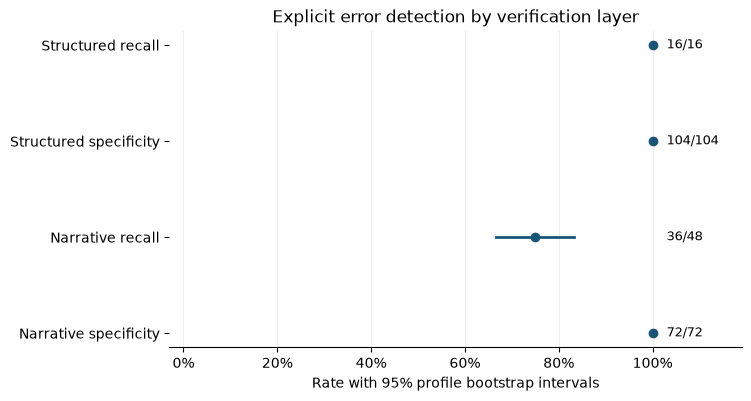

In [11]:
if analysis:
    layers = analysis["layers"]
    display(pd.DataFrame({k: layers[k]["confusion"] for k in ("structured", "narrative")}).T)
    for section in ("structured_checks", "narrative_checks"):
        display(metric_frame(layers[section]))
    display(pd.Series(layers["layer_controls"], name="Layer-specific gold cases"))
    show_figure("05_verification_layers")

## 12. Deterministic correction evaluation

A scripted responder exercises normal release, a fully corrected revision, partial
correction, an unchanged answer, a new error, invalid JSON, timeout, faithful ambiguous
prose, valid JSON with erroneous prose, false-rejection repair, and omission of the
probability. The intended claims and completeness are specified before each scripted
request. Fallback is independently checked against reference probability, signed
drivers and directions.

In [12]:
if correction:
    display(pd.DataFrame([{
        "scenario": r["scenario"], "requests": r["requests"], "original_gold": r["original_gold"],
        "revision_gold": r["revision_gold"], "delivery": r["trace"]["source"],
        "final_faithful": r["final_mathematically_faithful"], "final_complete": r["final_complete"],
    } for r in correction["rows"]]))

,scenario,requests,original_gold,revision_gold,delivery,final_faithful,final_complete
0,original_accepted,0,faithful,None,grounded_draft,True,True
1,fully_corrected,1,unfaithful,faithful,model_revision,True,True
2,partially_corrected,1,unfaithful,unfaithful,deterministic_fallback,True,True
3,unchanged,1,unfaithful,unfaithful,deterministic_fallback,True,True
4,new_error,1,unfaithful,unfaithful,deterministic_fallback,True,True
5,invalid_json,1,unfaithful,indeterminate,deterministic_fallback,True,True
6,timeout,1,unfaithful,None,deterministic_fallback,True,True
7,faithful_ambiguous_revision,1,unfaithful,faithful,deterministic_fallback,True,True
8,correct_drivers_wrong_prose,1,unfaithful,unfaithful,deterministic_fallback,True,True
9,faithful_false_rejection_repaired,1,faithful,faithful,model_revision,True,True


## 13. Optional live Qwen3 revisions

The checksummed selection contains 30 IDs, ten per preregistered stratum. Live mode
uses an already-running local Ollama instance, the recorded Qwen3 8B digest,
temperature 0, seed 42 and the frozen correction prompt. The cumulative request cap
and versioned owner-only checkpoint support resume. An interrupted reserved request
is recorded as unknown and is never replayed. The offline reference results use the
fixed challenge. A separate completed live run returned one revision for each of the
30 selected drafts. One human reviewer judged the revisions against the frozen
rubric and synthetic references while blinded to the gate decisions. The workbook,
crosswalk, checkpoint and final analysis remain in private storage.

In [13]:
if "live_plan" in run:
    display(pd.DataFrame(run["live_plan"]).groupby("stratum").size().rename("preregistered"))
if "live" in run:
    display(pd.Series(run["live"]["summary"]))

stratum
faithful_prose    10
incomplete        10
math_error        10
Name: preregistered, dtype: int64

## 14. Correction effectiveness and fallback

A successful full model correction starts from a mathematically false draft, yields a
faithful and complete revision under the independent rubric, and passes release.
A repaired false rejection starts from faithful prose and receives a faithful accepted
revision. Report deterministic delivery independently. Scripted latency measures local
software overhead only.

The live reviewer rated 28 of 30 revisions mathematically faithful and found all
30 complete and valid. Both unfaithful revisions put a lower-ranked driver first
in the structured list. The gate withheld both.

| Original draft stratum | Faithful, complete and valid revisions | Accepted by gate | Used fallback |
|---|---:|---:|---:|
| Mathematically unfaithful | 10/10 | 8/10 | 2/10 |
| Faithful prose withheld by gate | 8/10 | 2/10 | 8/10 |
| Faithful but incomplete | 10/10 | 6/10 | 4/10 |
| **Total** | **28/30** | **16/30** | **14/30** |

Qwen3 corrected all **10/10** original mathematical-error drafts under the human
rubric. The gate released **8/10** of those corrections. Overall, false rejection
was **12/28 (42.9%)** among faithful, complete and valid revisions. These 12
revisions had unparsed prose and no explicit attribution error in the gate trace.
False acceptance was **0/2** among unfaithful revisions. Fallback was used for
**14/30 (46.7%)**, including the two revisions with incorrect rank.

attempted                       11.000000
requests                        10.000000
valid_revisions                  8.000000
original_accepted                1.000000
original_correctly_rejected      9.000000
original_falsely_rejected        1.000000
accepted_revisions               3.000000
failed_revisions                 7.000000
fallback                         7.000000
pending_gold                     0.000000
genuinely_corrected              3.000000
accepted_genuine_corrections     2.000000
full_genuine_corrections         1.000000
false_rejection_repairs          1.000000
accepted_unfaithful              0.000000
rejected_faithful_revision       1.000000
new_errors                       1.000000
final_faithful                  11.000000
final_complete                  10.000000
latency_seconds                  0.000154
median_latency_seconds           0.000014
dtype: float64

,numerator,denominator,estimate
model_revision_success,1.0,9.0,0.111
false_rejection_repair,1.0,1.0,1.000
final_system_correctness,11.0,11.0,1.000
final_system_completeness,10.0,11.0,0.909
fallback_frequency,7.0,11.0,0.636


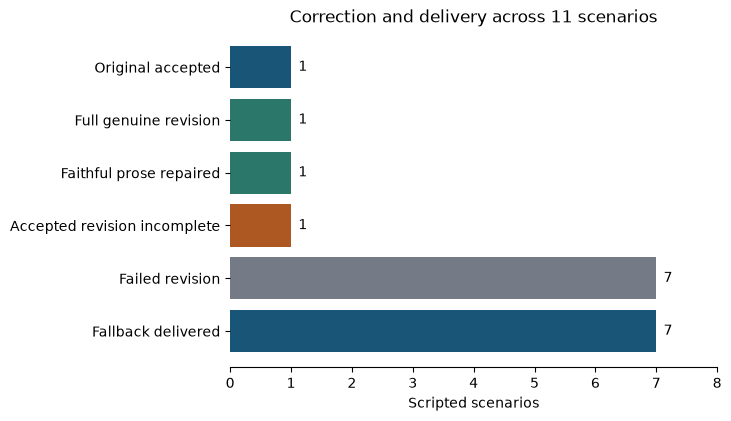

In [14]:
if correction:
    summary = correction["summary"]
    display(pd.Series({k: v for k, v in summary.items() if k != "rates"}))
    display(metric_frame(summary["rates"]))
    show_figure("06_corrections")

## 15. Optional saved LLM explanation audit

The secondary analysis awaits manual annotation. The worksheet exporter reads only
the pinned Experiment 2 or 3 checkpoint and its exact references. It uses the past
traces for sampling, then gives reviewers draft, revision or fallback text plus the
model reference without the verifier's findings. Worksheets, case crosswalks and real
MIMIC inputs stay private. Only the number of selected records and the input checksum
appear in the notebook.

In [15]:
if AUDIT_EXPERIMENT is not None:
    if AUDIT_DIRECTORY is None:
        raise ValueError("Set a dedicated private audit directory outside Git.")
    display(saved_prose_worksheet(AUDIT_DIRECTORY, AUDIT_EXPERIMENT))

## 16. Statistical uncertainty

The analysis uses 10,000 percentile bootstrap replicates with seed 3804. The resampling
unit is the fictional profile, including its coefficient reversals and all derived
responses. A paired estimate is direct acceptance minus paraphrase acceptance. Some
intervals collapse because the design produces the same result in all observed clusters.
With six clusters and fixed templates, such intervals carry no population-level guarantee.

In [16]:
if analysis:
    display(pd.Series(analysis["bootstrap"]))
    display(pd.DataFrame(analysis["paraphrases"]).drop(columns="pairs").round(3))

seed                    3804
replicates             10000
unit          paired_profile
dtype: object

,style,discordant,numerator,denominator,estimate,ci95_low,ci95_high,clusters
0,alias,0,0,6,0.0,0.0,0.0,6
1,compound,0,0,6,0.0,0.0,0.0,6
2,passive,6,6,6,1.0,1.0,1.0,6
3,pronoun,6,6,6,1.0,1.0,1.0,6
4,qualified,6,6,6,1.0,1.0,1.0,6
5,reference,6,6,6,1.0,1.0,1.0,6
6,relative,6,6,6,1.0,1.0,1.0,6
7,shared,6,6,6,1.0,1.0,1.0,6


## 17. Illustrative examples

The first example shows faithful prose withheld by the gate. The second contains an
incorrect feature direction embedded in a relative clause. Both were categorized as
unparsed instead of receiving an explicit semantic judgment.

In [17]:
if analysis:
    for example in analysis["examples"]:
        details = ", ".join(example["issues"])
        display(Markdown('\n'.join([
            f'**{example["challenge_id"]} · {example["gold"]}**', "",
            f'> {example["explanation"]}', "",
            f'Outcome **{example["outcome"]}**. Issue codes **{details}**.',
        ])))

**exp4-A-01-02 · faithful**

> The model estimates a 29.42% readmission probability. The predicted risk is raised by age; The predicted risk is raised by prior_admissions; The predicted risk is lowered by creatinine.

Outcome **ambiguous_or_unparsed**. Issue codes **missing_prose_drivers, unparsed**.

**exp4-B-02-01 · unfaithful**

> The model estimates a 4.34% readmission probability. age, which increases the model's predicted risk, is among the three leading drivers; prior_admissions, which decreases the model's predicted risk, is among the three leading drivers; creatinine, which increases the model's predicted risk, is among the three leading drivers.

Outcome **ambiguous_or_unparsed**. Issue codes **missing_prose_drivers, unparsed**.

## 18. Discussion and limitations

The reference run supports H4 on this challenge. The structured verifier caught all
16 structured errors. The standalone narrative check explicitly identified 36 of 48
prose-error cases. The combined checker identified 52 of 60 mathematically unfaithful
responses. It withheld the other eight as ambiguous, four passive and four
relative-clause contradictions. Four other cases combined a caught structured error
with an uncaught prose error. The release gate withheld 36 of 60 faithful complete
responses. All 36 had ambiguous clauses and missing parsed directions. Direct,
alias and compound wordings passed on this fixed set. The six other styles had
complete false rejection in the sampled forms.

The gate accepted an independently faithful revision that omitted the response
probability. Seven of the eleven scripted scenarios used fallback. This establishes
software behavior under the scripted cases. The live supplement likewise shows a
difference between mathematically successful model correction and release. Its
30 drafts were selected from already-rejected fictional examples across 11
references in six profiles. The wording mix and sample selection limit
generalization to naturally occurring prose. The single-reviewer design provides
no inter-reviewer agreement estimate, and two unfaithful live revisions give
little evidence about false acceptance on other revisions.

## 19. Experiment 5 handoff

Use the blinded worksheet and rubric to check agreement between human reviewers.
Collect separate judgments of mathematical faithfulness, completeness, clarity and
readability. Include matched direct and unfamiliar paraphrases, examples withheld as
ambiguous, and reference-aligned deterministic outputs. Use independent annotations of
private saved drafts and corrections to assess how often the synthetic failure modes
appear in actual Qwen3 prose. Preserve the baseline and challenge checksum for any
future verifier comparison.